# Diagnostica Random Forest Chen — training, testing e generalizzazione (59 funzioni)

**Scopo:** rispondere alle domande del ricevimento, mantenendo congelati **le 14 feature originali**, `RandomForestClassifier(random_state=42)` (senza tuning) e la ground truth GCP. Test per funzione, non per invocazione; tutte le osservazioni di una funzione rimangono nello stesso lato dello split.

**Analisi incluse:** (1) integrità/dataset/etichette; (2) ripetibilità dei profili x86; (3) split K-fold per funzione con metriche sul training e sul testing, per soglie 15% e 2,5%; (4) matrici di confusione e recall delle classi; (5) curve di apprendimento variando il numero di funzioni di training, senza cambiare i parametri RF; (6) elenco delle funzioni critiche e osservazioni sulla ground truth.

**Da distinguere:** il nostro LOFO precedente misura ogni funzione come sconosciuta, mentre K-fold considera più funzioni nuove per test fold. La accuracy **per funzione** usa il voto di maggioranza delle 100 predizioni x86 della stessa funzione; la accuracy **per campione** usa 100 osservazioni ripetute per funzione. Non trattare 5.900 campioni come 5.900 funzioni indipendenti.

**Attenzione:** questa diagnostica NON comprende l'addestramento dei regressori ARM del paper: si concentra sul classificatore ternario. Non cercare/tarare iperparametri a posteriori usando i fold di test.

In [1]:
# Eseguire da ~/Documenti/GitHub/serverledge con .venv-analysis attivo.
from pathlib import Path
import sys, hashlib, json, math, warnings
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display
from pathlib import Path


REPO = Path.home() / "Documenti/GitHub/serverledge"

os.chdir(REPO)

print("Directory di lavoro:", Path.cwd())

print("Directory corrente:", Path.cwd())
print("Interprete Python:", sys.executable)
print("Ambiente virtuale:", sys.prefix)
print("Repository:", REPO)


assert(REPO / "analysis/profiling/paper_original_prediction_pipeline.py").is_file(), "File del classificatore non trovato"
sys.path.insert(0,str(REPO/'analysis/profiling'))
from paper_original_prediction_pipeline import (load_inputs, DATASET_ROOT, PREDICTORS_14, MODEL_CLASSIFIER, majority_class, CLASSES)
print('RF originale:', RandomForestClassifier(**MODEL_CLASSIFIER).get_params())
print('Feature:', PREDICTORS_14)
print('Dataset:',DATASET_ROOT)

Directory di lavoro: /home/ale/Documenti/GitHub/serverledge
Directory corrente: /home/ale/Documenti/GitHub/serverledge
Interprete Python: /home/ale/Documenti/GitHub/serverledge/.venv-analysis/bin/python3
Ambiente virtuale: /home/ale/Documenti/GitHub/serverledge/.venv-analysis
Repository: /home/ale/Documenti/GitHub/serverledge
RF originale: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
Feature: ['totalMemory', 'freeMemory', 'frameworkRuntime', 'userRuntime', 'cpuUserDelta', 'cpuKernelDelta', 'cpuIdleDelta', 'cpuIOWaitDelta', 'cpuSoftIrqDelta', 'cpuStealDelta', 'pageFaultsDelta', 'utilizedCPUs', 'frameworkRuntimeDeltas', 'runt

In [2]:
# I file originali e i loro SHA256 sono controllati da load_inputs.
data,truth,manifest,_ = load_inputs(REPO/DATASET_ROOT)
x86=data.loc[data.machine_tag=='amd64'].copy().reset_index(drop=True)
assert len(x86)==5900 and len(truth)==59 and x86.function_name.nunique()==59
assert (x86.groupby('function_name').size()==100).all()
assert set(x86.function_name)==set(truth.function_name)
assert np.isfinite(x86[PREDICTORS_14].to_numpy(float)).all()
truth_index=truth.set_index('function_name').sort_index()
deltas=truth_index['arm_vs_x86_delta_percent'].astype(float)

def label_from_delta(values, tau):
    a=np.asarray(values,float)
    return np.where(a < -tau,'ARM-faster',np.where(a > tau,'ARM-slower','ARM-similar'))

labels={tau:pd.Series(label_from_delta(deltas.to_numpy(),tau), index=deltas.index)
        for tau in (15.0,2.5)}
assert (labels[15.0] == truth_index['paper_class_15']).all()
assert len(set(x86.function_name))==59
print('Funzioni:',len(truth), '| campioni x86:',len(x86))
for tau,y in labels.items():
    print(f'Soglia ±{tau}%:',y.value_counts().reindex(CLASSES,fill_value=0).to_dict())
print('Ground truth verificata: mediana GCP per funzione, non usata come feature predittiva')

Funzioni: 59 | campioni x86: 5900
Soglia ±15.0%: {'ARM-faster': 11, 'ARM-similar': 40, 'ARM-slower': 8}
Soglia ±2.5%: {'ARM-faster': 26, 'ARM-similar': 9, 'ARM-slower': 24}
Ground truth verificata: mediana GCP per funzione, non usata come feature predittiva


## 1 — Ground truth, margini rispetto alle soglie e stabilità dei profili

La ground truth deriva dalle **mediane della durata effettiva GCP** x86/ARM, che non sono necessariamente uguali al campo `runtime` del profiler SAAF. Qui controlliamo la distanza dalle soglie e la stabilità **dei profili x86** disponibili. Per verificare l'incertezza delle *etichette* con bootstrap delle mediane servirebbero le 100 durate GCP per architettura estratte dalla sorgente originale: **non ricaviamo questa incertezza dal solo runtime del profiler**.

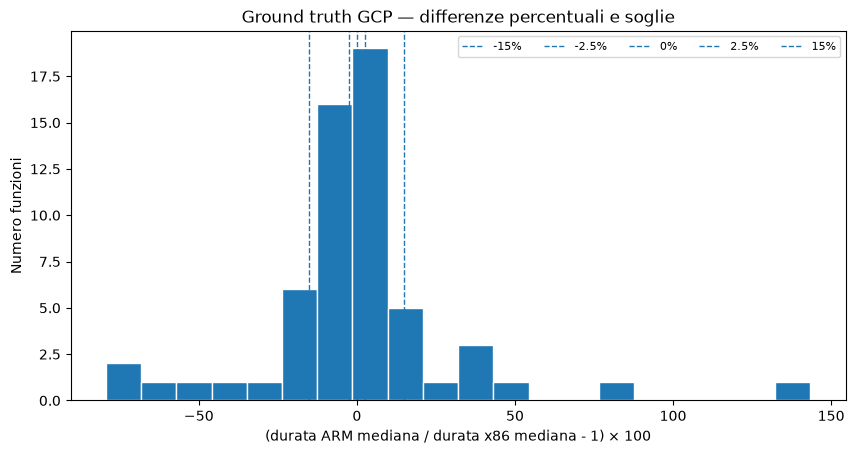

,function_name,threshold,delta_percent,distance_to_threshold_pp,label
112,tempfileio,2.5,-2.818415,0.318415,ARM-faster
117,vswarm-fibonacci,2.5,-2.996542,0.496542,ARM-faster
105,pointerchase,2.5,-3.082013,0.582013,ARM-faster
73,dynamic-html-py,2.5,-3.087469,0.587469,ARM-faster
86,graph-bfs,2.5,-1.912208,0.587792,ARM-similar
63,billibench-kmeans,2.5,-1.805840,0.694160,ARM-similar
106,pointerchase-py,2.5,3.337630,0.837630,ARM-slower
76,float-ops-node,2.5,-3.373384,0.873384,ARM-faster
16,filehandle,15.0,-15.912067,0.912067,ARM-faster
25,functionbench-sequential-disk-io,15.0,15.923312,0.923312,ARM-slower


In [3]:
fig,ax=plt.subplots(figsize=(10,4.8))
ax.hist(deltas,bins=20,edgecolor='white')
for limit in (-15,-2.5,0,2.5,15):ax.axvline(limit,linestyle='--',linewidth=1,label=f'{limit:g}%')
ax.set(xlabel='(durata ARM mediana / durata x86 mediana - 1) × 100',
       ylabel='Numero funzioni',title='Ground truth GCP — differenze percentuali e soglie')
ax.legend(ncol=5,fontsize=8);plt.show()

threshold_rows=[]
for tau in (15.,2.5):
    distance=np.abs(np.abs(deltas)-tau)
    threshold_rows.append(pd.DataFrame({'function_name':deltas.index,'threshold':tau,
        'delta_percent':deltas.to_numpy(),'distance_to_threshold_pp':distance.to_numpy(),
        'label':labels[tau].to_numpy()}))
near=pd.concat(threshold_rows,ignore_index=True)
display(near.sort_values('distance_to_threshold_pp').head(18))

,feature,median_iqr_over_abs_median_pct,functions_constant,functions_with_nonzero_median
8,cpuSoftIrqDelta,200.000000,0,8
7,cpuIOWaitDelta,115.000000,18,4
5,cpuKernelDelta,18.333333,0,54
10,pageFaultsDelta,14.262636,0,59
2,frameworkRuntime,10.114496,0,59
1,freeMemory,9.758435,0,59
12,frameworkRuntimeDeltas,8.280483,0,59
4,cpuUserDelta,2.716926,0,59
6,cpuIdleDelta,2.000000,0,59
13,runtime,1.848139,0,59


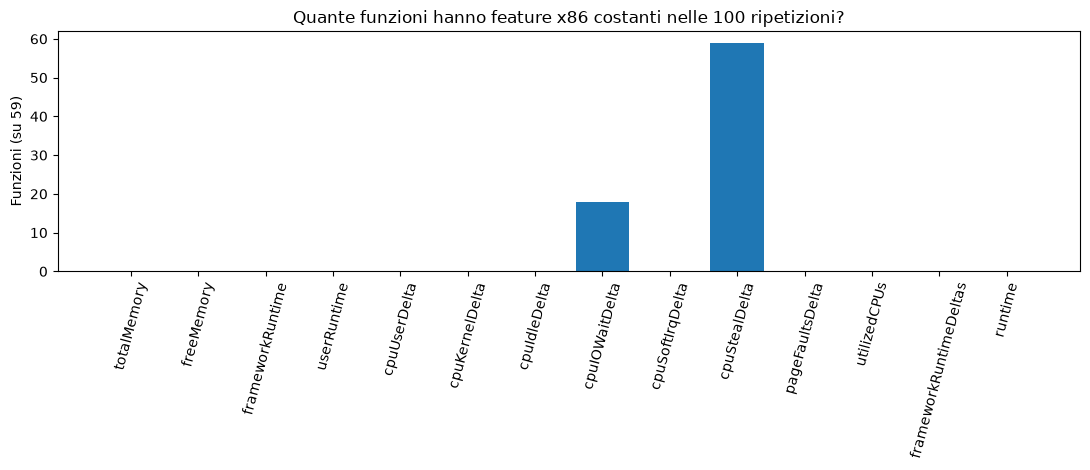

In [4]:
# Ripetibilità delle 100 osservazioni x86: IQR/mediana e quota di feature costanti.
feature_rows=[]
for feat in PREDICTORS_14:
    g=x86.groupby('function_name')[feat]
    q25=g.quantile(.25);q75=g.quantile(.75);median=g.median()
    spread=(q75-q25)/median.abs().replace(0,np.nan)*100
    feature_rows.append({'feature':feat,'median_iqr_over_abs_median_pct':spread.median(),
                         'functions_constant':int((g.nunique()==1).sum()),
                         'functions_with_nonzero_median':int((median!=0).sum())})
feature_spread=pd.DataFrame(feature_rows)
display(feature_spread.sort_values('median_iqr_over_abs_median_pct',ascending=False))
fig,ax=plt.subplots(figsize=(11,4.8))
ax.bar(feature_spread.feature,feature_spread.functions_constant)
ax.tick_params(axis='x',rotation=75)
ax.set(ylabel='Funzioni (su 59)',title='Quante funzioni hanno feature x86 costanti nelle 100 ripetizioni?')
plt.tight_layout();plt.show()

## 2 — Test effettivo per funzione: GroupKFold

**Nessuna fuga d'informazione**: per ogni fold, `set(train_functions) ∩ set(test_functions) = ∅`. Si allena su tutte le 100 osservazioni x86 per ogni funzione di training con l'etichetta della funzione. Il modello rimane esattamente `RandomForestClassifier(random_state=42)`.

Valutiamo anche il training per verificare se il modello riesce a riconoscere i pattern già visti; accuracy training elevata + accuracy test bassa suggerisce sovradattamento, ma **non prova** che l'unica causa sia overfitting. Confrontiamo anche una baseline che predice sempre la classe maggioritaria **del training fold**.

In [5]:
ORDER=list(CLASSES)
GROUPS=x86.function_name.to_numpy()
ALL_IND=np.arange(len(x86))
SPLITS=list(GroupKFold(n_splits=5).split(x86[PREDICTORS_14],groups=GROUPS))
assert all(not(set(GROUPS[tr])&set(GROUPS[te])) for tr,te in SPLITS)

# Voto di maggioranza delle 100 predizioni per funzione (stessa regola del paper).
def collapse_function_votes(frame, predictions, true_lookup):
    temp=pd.DataFrame({'function_name':frame['function_name'].to_numpy(),
                       'prediction':np.asarray(predictions)})
    byfn=temp.groupby('function_name',sort=True)['prediction'].apply(
        lambda s:majority_class(s.to_numpy()))
    true=true_lookup.loc[byfn.index]
    return pd.DataFrame({'function_name':byfn.index,'true':true.to_numpy(),'pred':byfn.to_numpy()})

def get_metrics(frame):
    a=(frame['true']==frame['pred']).to_numpy()
    recalls={f'recall_{cl}':(float((frame.loc[frame.true==cl,'pred']==cl).mean())
                if (frame.true==cl).any() else np.nan) for cl in ORDER}
    valid=np.array(list(recalls.values()),float)
    return {'accuracy':float(a.mean()),'balanced_recall':float(np.nanmean(valid)),**recalls}

cv_rows=[]; cv_pred=[];baseline_rows=[]
for tau in (15.,2.5):
    y_lookup=labels[tau]
    y_all=x86.function_name.map(y_lookup).to_numpy()
    for fold,(tr,te) in enumerate(SPLITS,1):
        tr_fn=set(GROUPS[tr]);te_fn=set(GROUPS[te]);assert tr_fn.isdisjoint(te_fn)
        model=RandomForestClassifier(**MODEL_CLASSIFIER)
        model.fit(x86.iloc[tr][PREDICTORS_14],y_all[tr])
        major=pd.Series(y_all[tr]).value_counts().idxmax()
        for split,idx in [('train',tr),('test',te)]:
            sample_predictions=model.predict(x86.iloc[idx][PREDICTORS_14])
            frame=collapse_function_votes(x86.iloc[idx],sample_predictions,y_lookup)
            metrics=get_metrics(frame)
            cv_rows.append({'tau':tau,'fold':fold,'set':split,'n_functions':len(frame),
                            'sample_accuracy':float(np.mean(sample_predictions==y_all[idx])),
                            **metrics})
            cv_pred.append(frame.assign(tau=tau,fold=fold,set=split))
            baseline_rows.append({'tau':tau,'fold':fold,'set':split,
                                  'baseline_majority_class_train':major,
                                  'baseline_function_accuracy':float((frame.true==major).mean())})
cv_results=pd.DataFrame(cv_rows)
cv_predictions=pd.concat(cv_pred,ignore_index=True)
cv_baselines=pd.DataFrame(baseline_rows)
display(cv_results[['tau','fold','set','n_functions','accuracy','sample_accuracy','balanced_recall']])
print('Medie per soglia e split:')
display(cv_results.groupby(['tau','set'])[['accuracy','sample_accuracy','balanced_recall']].agg(['mean','std']).round(4))
print('Baseline sempre-classe-maggioritaria-del-training-fold:')
display(cv_baselines.groupby(['tau','set']).baseline_function_accuracy.mean().round(4))

,tau,fold,set,n_functions,accuracy,sample_accuracy,balanced_recall
0,15.0,1,train,47,1.000000,1.000000,1.000000
1,15.0,1,test,12,0.416667,0.372500,0.238095
2,15.0,2,train,47,1.000000,1.000000,1.000000
3,15.0,2,test,12,0.666667,0.622500,0.458333
4,15.0,3,train,47,1.000000,1.000000,1.000000
5,15.0,3,test,12,0.583333,0.578333,0.291667
6,15.0,4,train,47,1.000000,1.000000,1.000000
7,15.0,4,test,12,0.500000,0.489167,0.285714
8,15.0,5,train,48,1.000000,1.000000,1.000000
9,15.0,5,test,11,0.818182,0.787273,0.450000


Medie per soglia e split:


accuracy         sample_accuracy         balanced_recall        
               mean     std            mean     std            mean     std
tau  set                                                                   
2.5  test    0.3394  0.1565          0.3213  0.1616          0.2759  0.1452
     train   1.0000  0.0000          1.0000  0.0000          1.0000  0.0000
15.0 test    0.5970  0.1548          0.5700  0.1546          0.3448  0.1021
     train   1.0000  0.0000          1.0000  0.0000          1.0000  0.0000

Baseline sempre-classe-maggioritaria-del-training-fold:


tau   set  
2.5   test     0.3909
      train    0.4449
15.0  test     0.6818
      train    0.6782
Name: baseline_function_accuracy, dtype: float64

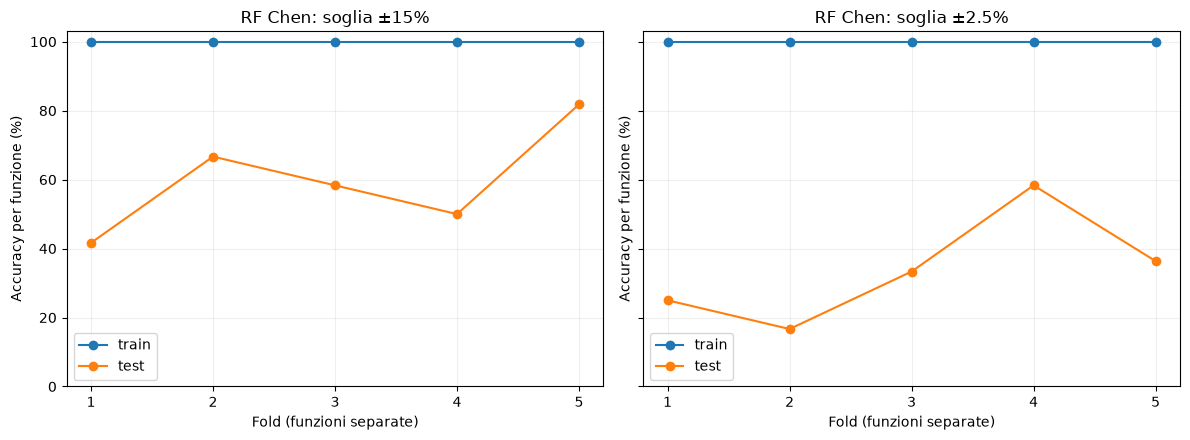

In [6]:
# Grafico 1: accuratezza train/test per ciascun fold.
fig,axes=plt.subplots(1,2,figsize=(12,4.5),sharey=True)
for ax,tau in zip(axes,(15.,2.5)):
    s=cv_results[cv_results.tau==tau]
    for part in ('train','test'):
        z=s[s.set==part].sort_values('fold')
        ax.plot(z.fold,z.accuracy*100,marker='o',label=part)
    ax.set(title=f'RF Chen: soglia ±{tau:g}%',xlabel='Fold (funzioni separate)',
           ylabel='Accuracy per funzione (%)',xticks=[1,2,3,4,5],ylim=(0,103))
    ax.legend();ax.grid(alpha=.2)
plt.tight_layout();plt.show()

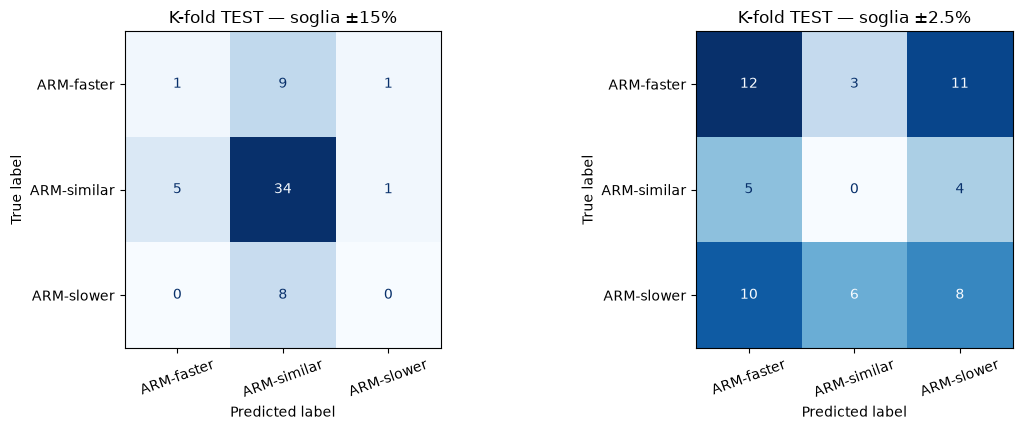

CLASSI TEST, tau=15: {'accuracy': 0.5932203389830508, 'balanced_recall': 0.31363636363636366, 'recall_ARM-faster': 0.09090909090909091, 'recall_ARM-similar': 0.85, 'recall_ARM-slower': 0.0}
Predizioni: {'ARM-faster': 6, 'ARM-similar': 51, 'ARM-slower': 2}
CLASSI TEST, tau=2.5: {'accuracy': 0.3389830508474576, 'balanced_recall': 0.26495726495726496, 'recall_ARM-faster': 0.46153846153846156, 'recall_ARM-similar': 0.0, 'recall_ARM-slower': 0.3333333333333333}
Predizioni: {'ARM-faster': 27, 'ARM-similar': 9, 'ARM-slower': 23}


In [7]:
# Grafico 2: matrici di confusione sui soli dati TEST, ogni funzione una sola volta.
fig,axes=plt.subplots(1,2,figsize=(12,4.4))
for ax,tau in zip(axes,(15.,2.5)):
    oof=cv_predictions[(cv_predictions.tau==tau)&(cv_predictions.set=='test')]
    assert oof.function_name.nunique()==59 and len(oof)==59
    cm=confusion_matrix(oof.true,oof.pred,labels=ORDER)
    ConfusionMatrixDisplay(cm,display_labels=ORDER).plot(ax=ax,cmap='Blues',colorbar=False,values_format='d')
    ax.set_title(f'K-fold TEST — soglia ±{tau:g}%')
    ax.tick_params(axis='x',rotation=20)
plt.tight_layout();plt.show()

# Recall per classe della valutazione fuori campione.
for tau in (15.,2.5):
    oof=cv_predictions[(cv_predictions.tau==tau)&(cv_predictions.set=='test')]
    print(f'CLASSI TEST, tau={tau:g}:',get_metrics(oof))
    print('Predizioni:',oof.pred.value_counts().reindex(ORDER,fill_value=0).to_dict())

## 3 — Curve di apprendimento: numero di funzioni di training

Manteniamo *fisso* il gruppo di test di ciascun fold; riduciamo soltanto il numero di funzioni nel training (senza cambiare nessun parametro RF). Una sottoselezione deterministica per fold e per dimensione produce un grafico descrittivo. **Non usiamo queste curve per selezionare una configurazione RF**: servono a capire se il problema diminuisce aumentando le funzioni distinte in training.

Per prove definitive più robuste si potranno aggiungere più estrazioni casuali di gruppi, sempre mantenendo separati i test fold.

mean    std
tau  n_train_functions set                
2.5  8                 test   0.442  0.166
                       train  1.000  0.000
     16                test   0.409  0.237
                       train  1.000  0.000
     24                test   0.371  0.159
                       train  1.000  0.000
     32                test   0.339  0.103
                       train  1.000  0.000
     40                test   0.305  0.150
                       train  1.000  0.000
     47                test   0.339  0.156
                       train  1.000  0.000
15.0 8                 test   0.479  0.172
                       train  1.000  0.000
     16                test   0.495  0.158
                       train  1.000  0.000
     24                test   0.542  0.172
                       train  1.000  0.000
     32                test   0.541  0.084
                       train  1.000  0.000
     40                test   0.511  0.165
                       train  1.000  0.000
     47                test   0.579  0.125
                       train  1.000  0.000

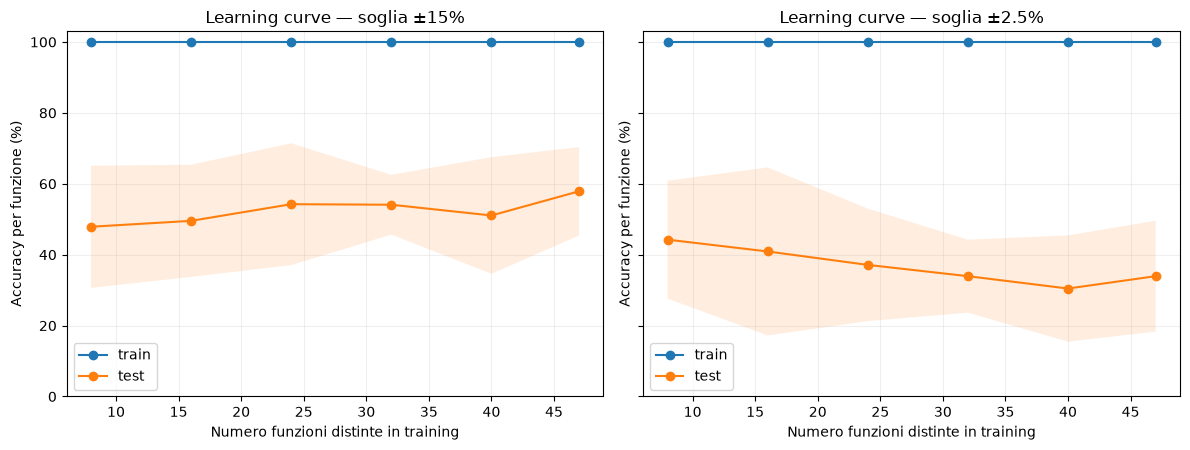

In [8]:
sizes=(8,16,24,32,40,47)
curve_rows=[]
for tau in (15.,2.5):
    y_lookup=labels[tau]
    all_y=x86.function_name.map(y_lookup).to_numpy()
    for fold,(train_all,test_idx) in enumerate(SPLITS,1):
        fn_train=np.array(sorted(set(GROUPS[train_all])))
        train_set=set(fn_train)
        for n in sizes:
            if n>len(fn_train):continue
            rng=np.random.default_rng(20261029+int(tau*10)*10000+fold*100+n)
            selected=set(rng.choice(fn_train,size=n,replace=False))
            idx=np.array([i for i in train_all if GROUPS[i] in selected])
            assert selected.issubset(train_set) and selected.isdisjoint(set(GROUPS[test_idx]))
            model=RandomForestClassifier(**MODEL_CLASSIFIER)
            model.fit(x86.iloc[idx][PREDICTORS_14],all_y[idx])
            for name,idx2 in [('train',idx),('test',test_idx)]:
                pred=model.predict(x86.iloc[idx2][PREDICTORS_14])
                f=collapse_function_votes(x86.iloc[idx2],pred,y_lookup)
                curve_rows.append({'tau':tau,'fold':fold,'n_train_functions':n,
                                   'set':name,'accuracy_function':get_metrics(f)['accuracy'],
                                   'n_test_functions':len(set(GROUPS[test_idx])),
                                   'classes_in_train':len(set(all_y[idx]))})
learning=pd.DataFrame(curve_rows)
display(learning.groupby(['tau','n_train_functions','set']).accuracy_function.agg(['mean','std']).round(3))
fig,axes=plt.subplots(1,2,figsize=(12,4.6),sharey=True)
for ax,tau in zip(axes,(15.,2.5)):
    for split in ('train','test'):
        sub=(learning[(learning.tau==tau)&(learning.set==split)]
             .groupby('n_train_functions').accuracy_function.agg(['mean','std']).reset_index())
        x=sub.n_train_functions.to_numpy()
        mean=sub['mean'].to_numpy()*100
        std=sub['std'].fillna(0).to_numpy()*100
        ax.plot(x,mean,marker='o',label=split)
        ax.fill_between(x,np.maximum(0,mean-std),np.minimum(100,mean+std),alpha=.13)
    ax.set(title=f'Learning curve — soglia ±{tau:g}%',xlabel='Numero funzioni distinte in training',
           ylabel='Accuracy per funzione (%)',ylim=(0,103))
    ax.legend();ax.grid(alpha=.2)
plt.tight_layout();plt.show()

## 4 — Errori e conclusioni verificabili

La tabella seguente mostra *quali* funzioni sono sbagliate nel K-fold; gli errori si confrontano con le distanze dalle soglie (funzioni borderline), senza utilizzare la ground truth per prendere decisioni nel training.

**Regole interpretative:** training alto / test basso = possibile overfitting/generalizzazione insufficiente; training e test entrambi bassi = dati poco separabili, modello incapace di apprendere, class imbalance o feature poco informative; test scarso sulle classi minori = verificare matrice di confusione. Nessuna di queste inferenze è una prova causale autonoma.

In [9]:
oof=cv_predictions[cv_predictions.set=='test'].copy()
oof['correct']=oof.true==oof.pred
oof=oof.merge(near.rename(columns={'threshold':'tau'})[['function_name','tau','delta_percent','distance_to_threshold_pp']],
              on=['function_name','tau'],validate='many_to_one')
print('Errori fuori campione per soglia (prima i casi vicini alla soglia):')
display(oof[~oof.correct].sort_values(['tau','distance_to_threshold_pp'])[
    ['tau','function_name','true','pred','delta_percent','distance_to_threshold_pp']].head(35))
print('Accuracy sui test grouped K-fold:',oof.groupby('tau').correct.mean())
print('Non equiparare questo numero all accuracy LOFO o al 93,35% pubblicato da Chen: dataset e protocollo diversi.')

Errori fuori campione per soglia (prima i casi vicini alla soglia):


,tau,function_name,true,pred,delta_percent,distance_to_threshold_pp
69,2.5,tempfileio,ARM-faster,ARM-slower,-2.818415,0.318415
92,2.5,pointerchase,ARM-faster,ARM-slower,-3.082013,0.582013
109,2.5,dynamic-html-py,ARM-faster,ARM-slower,-3.087469,0.587469
76,2.5,graph-bfs,ARM-similar,ARM-faster,-1.912208,0.587792
107,2.5,billibench-kmeans,ARM-similar,ARM-slower,-1.805840,0.694160
60,2.5,compression,ARM-slower,ARM-faster,3.480706,0.980706
71,2.5,base64stream,ARM-similar,ARM-faster,1.470475,1.029525
62,2.5,float-ops-py,ARM-slower,ARM-faster,3.533319,1.033319
94,2.5,thumbnailer-py,ARM-slower,ARM-faster,3.557465,1.057465
89,2.5,graph-mst-py,ARM-slower,ARM-faster,3.581052,1.081052


Accuracy sui test grouped K-fold: tau
2.5     0.338983
15.0    0.593220
Name: correct, dtype: float64
Non equiparare questo numero all accuracy LOFO o al 93,35% pubblicato da Chen: dataset e protocollo diversi.


In [10]:
# Export FACOLTATIVO: non sovrascrive i risultati congelati.
EXPORT = False
OUT = REPO/'data/architecture-comparison/diagnostics/rf-train-test-kfold-59-v1'
if EXPORT:
    if OUT.exists():
        raise FileExistsError(f'Destinazione gia presente: {OUT}; non sovrascrivo')
    OUT.mkdir(parents=True,exist_ok=False)
    cv_results.to_csv(OUT/'cv_train_test_metrics.csv',index=False)
    cv_predictions.to_csv(OUT/'cv_train_test_by_function.csv',index=False)
    cv_baselines.to_csv(OUT/'cv_baselines.csv',index=False)
    learning.to_csv(OUT/'learning_curves.csv',index=False)
    feature_spread.to_csv(OUT/'feature_stability_x86.csv',index=False)
    near.to_csv(OUT/'distance_from_threshold.csv',index=False)
    oof.to_csv(OUT/'cv_test_errors.csv',index=False)
    (OUT/'methodology.json').write_text(json.dumps({
        'dataset_manifest_sha256':hashlib.sha256((REPO/DATASET_ROOT/'dataset_manifest.json').read_bytes()).hexdigest(),
        'classification_features':PREDICTORS_14,
        'rf_params':MODEL_CLASSIFIER,
        'split':'GroupKFold(n_splits=5), groups=function_name',
        'learning_curve_sizes_functions':list(sizes),
        'note':'No tuning, no ARM target leakage, per-function vote, target label for evaluation only.'
    },indent=2)+'\n',encoding='utf-8')
    print('Creati CSV:',OUT)
else:
    print('Analisi completata in memoria. Imposta EXPORT=True solo per esportare in una cartella nuova.')

Analisi completata in memoria. Imposta EXPORT=True solo per esportare in una cartella nuova.


## 5 — Domande da portare ai professori

1. Qual è il divario tra accuracy training e test sulle 59 funzioni? Cambia fra 15% e 2,5%?
2. La RF supera la baseline della classe maggioritaria **nel test per funzione**?
3. Aumentando il numero di funzioni distinte in training, l'accuracy test migliora?
4. Quali classi e quali funzioni generano gli errori? Sono vicine alla soglia oppure lontane?
5. Le feature x86 presentano realmente informazione discriminante inter-funzione? Le osservazioni risultano stabili?
6. **Controllo successivo dei campioni ARM**: dalla sorgente delle 100 durate native, verificare robustezza delle mediane/etichette con bootstrap per funzione e architettura (non usare `runtime` del profiler come surrogato della duration GCP).

**Non cambiare feature, modello o iperparametri sulla base dei dati di test prima di concordare un protocollo nuovo.**

## 6 — Prova A: quanti campioni per funzione servono davvero?

Manteniamo **RandomForestClassifier(**MODEL_CLASSIFIER)** invariato (14 feature, random_state=42).

Per ogni fold *GroupKFold* già definito, addestriamo su **1, 5, 10, 25, 50 o 100 osservazioni x86 per funzione**. Tutte le funzioni del test restano interamente fuori dal training; in test utilizziamo sempre le **100 osservazioni per funzione**. Ripetiamo la sottoselezione casuale.

L'obiettivo è diagnosticare l'effetto della ridondanza delle osservazioni, **non** selezionare retroattivamente il numero che massimizza il test. I risultati sono esplorativi: se una quantità viene scelta dopo aver esaminato il test, occorre una successiva valutazione indipendente.

**Avvertenza:** questa sezione avvia diversi addestramenti; nessun file è modificato.

,tau,n_samples_per_function,split,count,mean,std
0,2.5,1,test,10,0.3811,0.1254
1,2.5,1,train,10,1.0000,0.0000
2,2.5,5,test,10,0.3720,0.0652
3,2.5,5,train,10,1.0000,0.0000
4,2.5,10,test,10,0.3553,0.0920
5,2.5,10,train,10,1.0000,0.0000
6,2.5,25,test,10,0.3477,0.1222
7,2.5,25,train,10,1.0000,0.0000
8,2.5,50,test,10,0.3227,0.0966
9,2.5,50,train,10,1.0000,0.0000


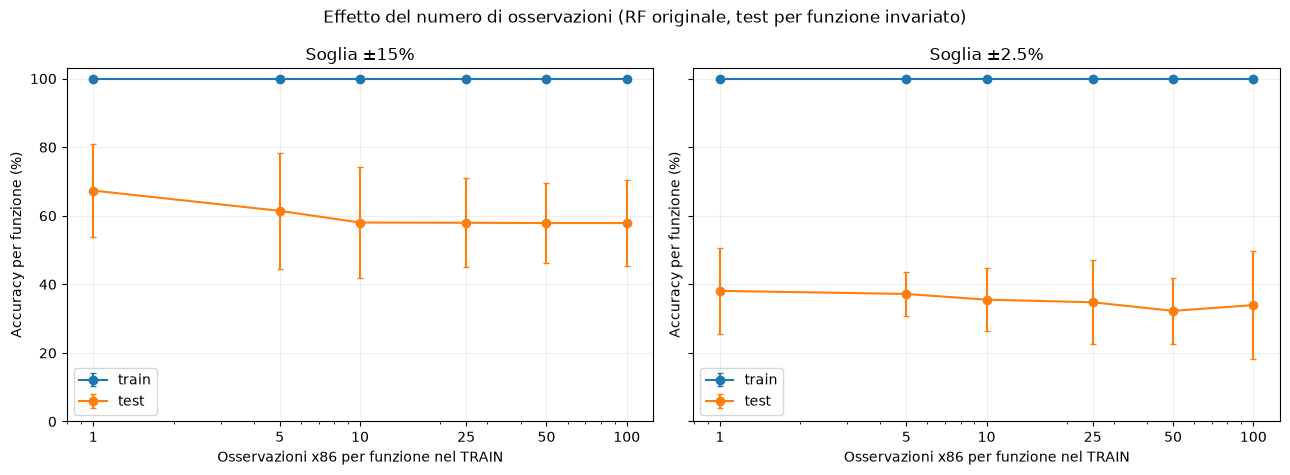

PASS: campionamento per funzione, 100 osservazioni/funzione invarianti in TEST


In [11]:
# 2 ripetizioni e 5 GroupKFold: confronto sulla stessa identica popolazione di test.
from collections import Counter
SAMPLE_LEVELS=(1,5,10,25,50,100)
SAMPLE_REPEATS=2
thin_rows=[]
for tau in (15.,2.5):
    y_lookup=labels[tau]
    y_all=x86.function_name.map(y_lookup).to_numpy()
    for fold,(tr,te) in enumerate(SPLITS,1):
        sub=x86.iloc[tr]
        train_fns=sorted(sub.function_name.unique())
        assert not(set(train_fns)&set(x86.iloc[te].function_name.unique()))
        fn_indices={fn:np.flatnonzero(GROUPS==fn) for fn in train_fns}
        assert all(len(ii)==100 for ii in fn_indices.values())
        for nobs in SAMPLE_LEVELS:
            for repeat in range(SAMPLE_REPEATS if nobs < 100 else 1):
                rng=np.random.default_rng(20261029+int(tau*10)*10000+fold*100+nobs*7+repeat)
                idx=np.concatenate([rng.choice(fn_indices[fn], size=nobs,replace=False) for fn in train_fns])
                assert set(idx).issubset(set(tr)) and not(set(idx)&set(te))
                model=RandomForestClassifier(**MODEL_CLASSIFIER)
                model.fit(x86.iloc[idx][PREDICTORS_14],y_all[idx])
                for split,where in [('train',idx),('test',te)]:
                    preds=model.predict(x86.iloc[where][PREDICTORS_14])
                    per_fn=collapse_function_votes(x86.iloc[where],preds,y_lookup)
                    stats=get_metrics(per_fn)
                    thin_rows.append(dict(tau=tau,fold=fold,n_samples_per_function=nobs,
                                         repeat=repeat,split=split,
                                         n_train_functions=len(train_fns),
                                         n_test_functions=len(set(GROUPS[te])),
                                         accuracy_function=stats['accuracy'],
                                         balanced_recall=stats['balanced_recall'],
                                         sample_accuracy=float(np.mean(preds==y_all[where])),
                                         **{f'recall_{k.replace("-","_")}':stats[f'recall_{k}'] for k in CLASSES}))
thinning=pd.DataFrame(thin_rows)
assert len(thinning) == 2*5*(5*2+1)*2
summ_thinning=(thinning.groupby(['tau','n_samples_per_function','split'])
               .accuracy_function.agg(['count','mean','std']).reset_index())
display(summ_thinning.round(4))
fig,axes=plt.subplots(1,2,figsize=(13,4.8),sharey=True)
for ax,tau in zip(axes,(15.,2.5)):
    for split in ['train','test']:
        s=summ_thinning[(summ_thinning.tau==tau)&(summ_thinning.split==split)]
        ax.errorbar(s.n_samples_per_function,s['mean']*100,
                    yerr=s['std'].fillna(0)*100,marker='o',capsize=2,label=split)
    ax.set(xscale='log',xticks=SAMPLE_LEVELS,xticklabels=SAMPLE_LEVELS,
           xlabel='Osservazioni x86 per funzione nel TRAIN',
           title=f'Soglia ±{tau:g}%',ylabel='Accuracy per funzione (%)',ylim=(0,103))
    ax.legend();ax.grid(alpha=.2)
fig.suptitle('Effetto del numero di osservazioni (RF originale, test per funzione invariato)')
plt.tight_layout();plt.show()
print('PASS: campionamento per funzione, 100 osservazioni/funzione invarianti in TEST')

## 7 — Prova B: learning curve con più sottoselezioni

La precedente learning curve utilizza **una sola** sottoselezione per dimensione e fold. Qui ripetiamo le sottoselezioni indipendenti mantenendo **fissi i cinque gruppi di testing**, sempre sconosciuti al training. Il risultato indica quanto una curva dipenda dalla particolare scelta delle funzioni disponibili, non fornisce un nuovo test indipendente. Non si fa tuning.

I valori medi vanno letti insieme alla variabilità fra i tentativi e confrontati con la baseline del fold.

,tau,n_train_functions,accuracy_mean,accuracy_std,baseline_mean,balanced_recall_mean,runs
0,2.5,8,0.3960,0.1233,0.4343,0.3295,15
1,2.5,24,0.2990,0.1248,0.3843,0.2821,15
2,2.5,40,0.3768,0.1752,0.3798,0.3205,15
3,2.5,47,0.3333,0.1457,0.3788,0.2714,15
4,15.0,8,0.5227,0.1399,0.6818,0.3699,15
5,15.0,24,0.5328,0.1281,0.6818,0.3561,15
6,15.0,40,0.5308,0.0766,0.6818,0.3217,15
7,15.0,47,0.5909,0.1350,0.6818,0.3414,15


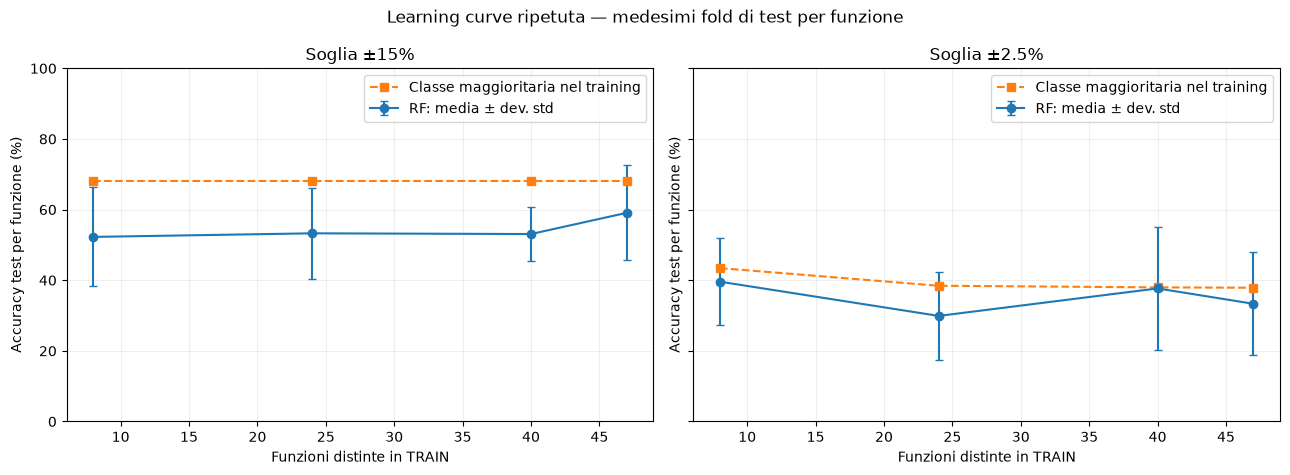

PASS: nessuna funzione di test è stata usata per addestrare RF


In [12]:
REPEATED_SIZES=(8,24,40,47)
REPEATED_SUBSETS=3
repeat_curve_rows=[]
for tau in (15.,2.5):
    y_lookup=labels[tau]
    y_all=x86.function_name.map(y_lookup).to_numpy()
    for fold,(tr,te) in enumerate(SPLITS,1):
        funcs=np.array(sorted(set(GROUPS[tr])))
        for n_fn in REPEATED_SIZES:
            assert n_fn <= len(funcs)
            for rep in range(REPEATED_SUBSETS):
                rng=np.random.default_rng(20261030+int(tau*10)*10000+fold*10000+n_fn*33+rep)
                chosen=set(rng.choice(funcs,size=n_fn,replace=False))
                ind=np.asarray([i for i in tr if GROUPS[i] in chosen])
                assert len(ind)==100*n_fn and not(set(GROUPS[te])&chosen)
                model=RandomForestClassifier(**MODEL_CLASSIFIER)
                model.fit(x86.iloc[ind][PREDICTORS_14],y_all[ind])
                pred=model.predict(x86.iloc[te][PREDICTORS_14])
                frame=collapse_function_votes(x86.iloc[te],pred,y_lookup)
                stats=get_metrics(frame)
                major=pd.Series(y_all[ind]).value_counts().idxmax()
                repeat_curve_rows.append(dict(tau=tau,fold=fold,rep=rep,
                    n_train_functions=n_fn,n_test_functions=len(frame),
                    classes_in_train=len(set(y_all[ind])),
                    accuracy_test=stats['accuracy'],
                    balanced_recall_test=stats['balanced_recall'],
                    majority_baseline_test=float((frame.true==major).mean())))
rep_curve=pd.DataFrame(repeat_curve_rows)
assert len(rep_curve)==2*5*len(REPEATED_SIZES)*REPEATED_SUBSETS
summ_rep=(rep_curve.groupby(['tau','n_train_functions'])
          .agg(accuracy_mean=('accuracy_test','mean'),accuracy_std=('accuracy_test','std'),
               baseline_mean=('majority_baseline_test','mean'),
               balanced_recall_mean=('balanced_recall_test','mean'),runs=('accuracy_test','size'))
          .reset_index())
display(summ_rep.round(4))
fig,axes=plt.subplots(1,2,figsize=(13,4.8),sharey=True)
for ax,tau in zip(axes,(15.,2.5)):
    s=summ_rep[summ_rep.tau==tau]
    ax.errorbar(s.n_train_functions,s.accuracy_mean*100,
                yerr=s.accuracy_std.fillna(0)*100,marker='o',capsize=3,label='RF: media ± dev. std')
    ax.plot(s.n_train_functions,s.baseline_mean*100,linestyle='--',marker='s',
            label='Classe maggioritaria nel training')
    ax.set(title=f'Soglia ±{tau:g}%',xlabel='Funzioni distinte in TRAIN',
           ylabel='Accuracy test per funzione (%)',ylim=(0,100))
    ax.legend();ax.grid(alpha=.2)
fig.suptitle('Learning curve ripetuta — medesimi fold di test per funzione')
plt.tight_layout();plt.show()
print('PASS: nessuna funzione di test è stata usata per addestrare RF')

## 8 — Bootstrap della ground truth GCP (CSV originali)

La campagna ha conservato gli `experiment_results.csv` per architettura, round e funzione. Ogni CSV registra la durata **server-side** `duration_s` (secondi), oltre ai flag `is_warm_start`, `execution_succeeded`, `profile_valid` ed `exclusive_container`. Non si usa `locust_response_time_ms` né la feature `runtime`.

Ricostruiamo **5 round × 20 campioni warm/validi** per ciascuna delle 59 funzioni e per ciascuna architettura. Prima di qualsiasi bootstrap controlliamo conteggi, provenance e corrispondenza numerica delle mediane con la ground truth congelata. Se qualcosa non coincide, ci fermiamo per diagnosticare la selezione, senza forzare i risultati.


In [13]:
# STEP C1 — Ricostruzione verificata dei 100 tempi originali per funzione/architettura.
# Non sostituire duration_s con locust_response_time_ms o con la feature runtime.
from collections import defaultdict
import csv

RAW_DIR = REPO / 'data/profiling/gcp-paper-rf-schema6/campaign/paper_rf_schema6_final/blocks'
assert RAW_DIR.is_dir(), f'Cartella non trovata: {RAW_DIR}'
raw_files = sorted(RAW_DIR.glob('*/round_*/*/experiment_results.csv'))
print('CSV originali trovati:', len(raw_files))
assert raw_files, 'Nessun experiment_results.csv: non si può procedere al bootstrap.'

expected_fns = set(truth_index.index)
ARCHS = ('amd64', 'arm64')
ROUNDS = {f'round_{i:03d}' for i in range(5)}
expected_keys = {(fn, arch) for fn in expected_fns for arch in ARCHS}

all_durations = defaultdict(list)
blocks_seen = set()
block_rows = []

required_fields = {
    'function', 'sample_index', 'duration_s', 'is_warm_start',
    'execution_succeeded', 'node_arch', 'status_code', 'policy',
    'profile_valid', 'exclusive_container'
}

def yes(value):
    return str(value).strip().lower() == 'true'

for path in raw_files:
    relative = path.relative_to(RAW_DIR)
    if len(relative.parts) != 4:
        raise ValueError(f'Layout non riconosciuto: {relative}')
    arch, round_name, fn, filename = relative.parts
    assert arch in ARCHS, (relative, arch)
    assert round_name in ROUNDS, f'Round fuori protocollo: {relative}'
    assert filename == 'experiment_results.csv', relative
    # Le eventuali altre 8 funzioni non partecipano al confronto comune-59.
    if fn not in expected_fns:
        continue
    block_key = (fn, arch, round_name)
    assert block_key not in blocks_seen, f'Blocco duplicato: {block_key}'
    blocks_seen.add(block_key)
    n_rows = 0
    selected = []
    with path.open(newline='', encoding='utf-8') as handle:
        reader = csv.DictReader(handle)
        missing = required_fields - set(reader.fieldnames or ())
        assert not missing, f'Colonne mancanti {missing}: {relative}'
        for row in reader:
            n_rows += 1
            assert row['function'] == fn, f'Funzione errata: {relative}, {row["function"]}'
            assert row['node_arch'] == arch, f'Architettura errata: {relative}, {row["node_arch"]}'
            # Non considerare cold, errori, profili incompleti/non esclusivi.
            valid = (yes(row['is_warm_start']) and
                     yes(row['execution_succeeded']) and
                     yes(row['profile_valid']) and
                     yes(row['exclusive_container']) and
                     str(row['status_code']).strip() == '200')
            if not valid:
                continue
            assert row['policy'] == 'RoundRobin', (relative, row['policy'])
            seconds = float(row['duration_s'])
            assert np.isfinite(seconds) and seconds > 0, (relative, seconds)
            selected.append(seconds * 1000.0)  # seconds -> milliseconds
    block_rows.append({'function_name': fn, 'machine_tag': arch,
                       'round': round_name, 'total_rows': n_rows,
                       'selected_warm_valid': len(selected)})
    # Ogni round della campagna finale ha 20 campioni selezionati, non 20 righe arbitrarie.
    if len(selected) != 20:
        print(f'BLOCCO NON CONFORME: {relative} | righe={n_rows} | validi={len(selected)}')
        raise ValueError('Conteggio warm/validi inatteso: confrontare con la selezione della campagna')
    all_durations[(fn, arch)].extend(selected)

block_summary = pd.DataFrame(block_rows)
expected_blocks = {(fn, a, rnd) for fn, a in expected_keys for rnd in ROUNDS}
assert blocks_seen == expected_blocks, (
    f'Blocchi trovati {len(blocks_seen)} contro {len(expected_blocks)}; '
    f'mancanti={sorted(expected_blocks-blocks_seen)[:10]}')
assert len(block_summary) == 59 * 2 * 5
wrong_counts = {(fn, arch):len(all_durations[(fn,arch)]) for fn,arch in expected_keys
                if len(all_durations[(fn,arch)]) != 100}
assert not wrong_counts, f'Non ci sono 100 campioni per architettura: {list(wrong_counts.items())[:10]}'

# Controllo forte: le mediane ricostruite devono RIPRODURRE quelle congelate.
med_x = np.array([np.median(all_durations[(fn,'amd64')]) for fn in truth_index.index], float)
med_a = np.array([np.median(all_durations[(fn,'arm64')]) for fn in truth_index.index], float)
truth_x = truth_index.x86_median_duration_ms.to_numpy(float)
truth_a = truth_index.arm_median_duration_ms.to_numpy(float)
err_x = float(np.max(np.abs(med_x-truth_x)))
err_a = float(np.max(np.abs(med_a-truth_a)))
print('Blocchi validati:', len(block_summary), '| 100 warm validi per funzione e architettura')
print(f'Errore massimo mediana x86: {err_x:.9g} ms | ARM: {err_a:.9g} ms')
if not np.allclose(med_x, truth_x, rtol=1e-9, atol=1e-6) or not np.allclose(med_a, truth_a, rtol=1e-9, atol=1e-6):
    mismatches = pd.DataFrame({
        'function_name': truth_index.index,
        'x86_original': truth_x, 'x86_csv': med_x,
        'arm_original': truth_a, 'arm_csv': med_a,
        'err_x86': np.abs(med_x-truth_x), 'err_arm': np.abs(med_a-truth_a)
    })
    display(mismatches.nlargest(10, 'err_x86'))
    display(mismatches.nlargest(10, 'err_arm'))
    raise ValueError('Mediane non coincidenti: NON procedere al bootstrap; controllare provenance/selezione')

HAS_RAW_BOOTSTRAP = True
print('PASS: 59 funzioni × 2 architetture × 100 campioni validi; mediane originali confermate')


CSV originali trovati: 670
Blocchi validati: 590 | 100 warm validi per funzione e architettura
Errore massimo mediana x86: 1.8189894e-12 ms | ARM: 4.54747351e-13 ms
PASS: 59 funzioni × 2 architetture × 100 campioni validi; mediane originali confermate


Soglia ±15%: stabilità mediana=1.000; funzioni con agreement<0.95=0/59; agreement<0.8=0/59


,function_name,true_class,delta_percent,bootstrap_label_agreement,delta_boot_ci_low,delta_boot_ci_high
32,filehandle,ARM-faster,-15.9121,0.9565,-16.4182,-14.5769
90,mutexcontention,ARM-similar,11.8860,0.9920,10.8404,14.5961
12,billibench-linear-regression,ARM-similar,-13.2978,0.9940,-14.5131,-12.4367
88,memory-rw-py,ARM-similar,12.6247,0.9995,11.4050,13.6034
0,amd_faster,ARM-slower,40.7256,1.0000,40.4666,41.0533
2,arm_faster,ARM-faster,-16.7392,1.0000,-16.8238,-16.6196
4,base64stream,ARM-similar,1.4705,1.0000,1.3963,1.5889
6,base64stream-py,ARM-similar,-4.7975,1.0000,-5.4089,-4.0097
8,billibench-kmeans,ARM-similar,-1.8058,1.0000,-2.6276,-0.8913
10,billibench-knn,ARM-faster,-61.9320,1.0000,-62.3623,-61.6848


Soglia ±2.5%: stabilità mediana=1.000; funzioni con agreement<0.95=4/59; agreement<0.8=1/59


,function_name,true_class,delta_percent,bootstrap_label_agreement,delta_boot_ci_low,delta_boot_ci_high
107,tempfileio,ARM-faster,-2.8184,0.6830,-5.1305,-0.8325
55,graph-bfs,ARM-similar,-1.9122,0.8120,-3.2494,0.0881
93,pointerchase,ARM-faster,-3.0820,0.8725,-4.2321,-2.0843
87,memory-rw-node,ARM-similar,0.4460,0.8735,-2.2313,4.3872
9,billibench-kmeans,ARM-similar,-1.8058,0.9600,-2.6276,-0.8913
61,graph-mst,ARM-similar,0.7271,0.9620,-0.4684,2.6606
29,dynamic-html-py,ARM-faster,-3.0875,0.9965,-3.3484,-2.8487
63,graph-mst-py,ARM-slower,3.5811,0.9995,2.9672,4.2791
69,graph-pagerank-py,ARM-slower,11.6103,0.9995,7.8187,13.6324
117,vswarm-fibonacci,ARM-faster,-2.9965,0.9995,-3.2556,-2.7253


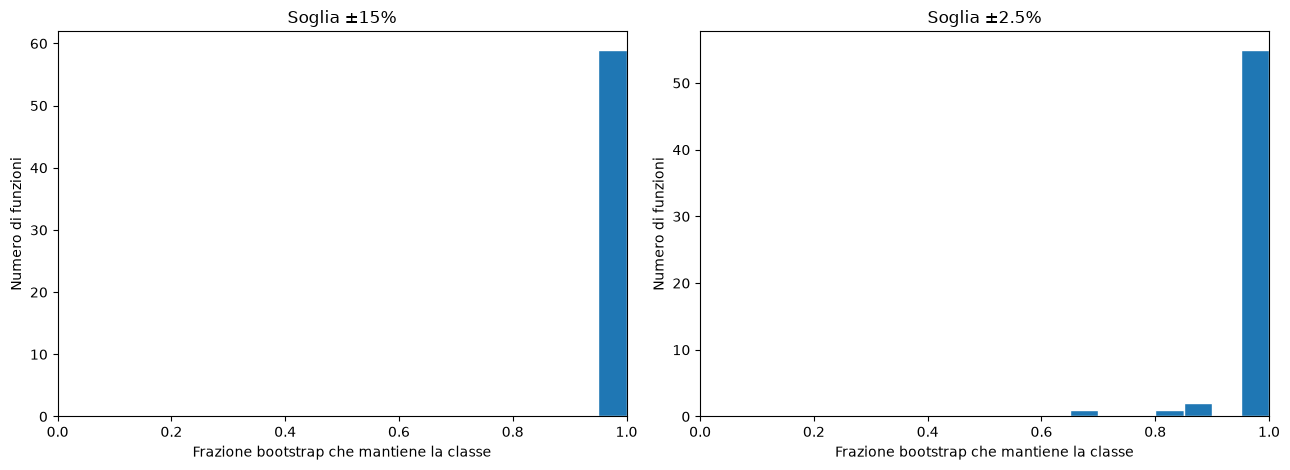

PASS: bootstrap su durate originali GCP; metriche descrittive, nessuna nuova misura


In [14]:
# STEP C2: solo se la provenienza dei 100 tempi per architettura è stata confermata.
if not HAS_RAW_BOOTSTRAP:
    print('SKIP: bootstrap non eseguito perché mancano le durate GCP originali verificate.')
    print('Le analisi RF restano invariate; nessuna stima di stabilità etichette viene inventata.')
else:
    # Eseguire questa cella SOLO dopo il PASS della precedente: nessuna modifica dei dati.
    B=2000
    rng=np.random.default_rng(20261029)
    bootstrap_rows=[]
    for fn in truth_index.index:
        x=np.asarray(all_durations[(fn,'amd64')],float)
        a=np.asarray(all_durations[(fn,'arm64')],float)
        ix=rng.integers(0,100,size=(B,100))
        ia=rng.integers(0,100,size=(B,100))
        boot_x=np.median(x[ix],axis=1)
        boot_a=np.median(a[ia],axis=1)
        boot_delta=100*(boot_a/boot_x-1)
        actual=float(deltas.loc[fn])
        for tau in (15.,2.5):
            nominal=str(label_from_delta([actual],tau)[0])
            boot_labels=label_from_delta(boot_delta,tau)
            counts=pd.Series(boot_labels).value_counts().reindex(CLASSES,fill_value=0)
            bootstrap_rows.append(dict(function_name=fn,tau=tau,delta_percent=actual,
              true_class=nominal,bootstrap_label_agreement=float(np.mean(boot_labels==nominal)),
              delta_boot_ci_low=float(np.quantile(boot_delta,.025)),
              delta_boot_ci_high=float(np.quantile(boot_delta,.975)),
              **{f'prob_{k.replace("-","_")}':float(counts.loc[k]/B) for k in CLASSES}))
    boot_labels_df=pd.DataFrame(bootstrap_rows)
    for tau in (15.,2.5):
        s=boot_labels_df[boot_labels_df.tau==tau]
        print(f'Soglia ±{tau:g}%: stabilità mediana={s.bootstrap_label_agreement.median():.3f}; '
              f'funzioni con agreement<0.95={(s.bootstrap_label_agreement<.95).sum()}/59; '
              f'agreement<0.8={(s.bootstrap_label_agreement<.8).sum()}/59')
        display(s.nsmallest(12,'bootstrap_label_agreement')
                [['function_name','true_class','delta_percent','bootstrap_label_agreement',
                  'delta_boot_ci_low','delta_boot_ci_high']].round(4))
    fig,axes=plt.subplots(1,2,figsize=(13,4.8))
    for ax,tau in zip(axes,(15.,2.5)):
        s=boot_labels_df[boot_labels_df.tau==tau]
        ax.hist(s.bootstrap_label_agreement,bins=np.linspace(0,1,21),edgecolor='white')
        ax.set(title=f'Soglia ±{tau:g}%',xlabel='Frazione bootstrap che mantiene la classe',
               ylabel='Numero di funzioni',xlim=(0,1))
    plt.tight_layout();plt.show()
    print('PASS: bootstrap su durate originali GCP; metriche descrittive, nessuna nuova misura')


### Interpretazione e prossimi passi

- Se TRAIN resta al 100% ma TEST è basso: forte divario di generalizzazione, non automaticamente una causa unica.
- Se meno osservazioni x86 migliorano TEST: indizio di ridondanza/sovradattamento ai profili noti, non prova definitiva; per scegliere la quantità corretta usare una validazione interna.
- Se aumentando funzioni diverse TEST migliora stabilmente: più workload/funzioni possono aiutare; ripetere e riportare la dispersione.
- Se il bootstrap mostra classi instabili: una parte del problema dipende dalla posizione delle funzioni vicino alle soglie.
- Se il bootstrap mostra classi stabili, ma la generalizzazione è bassa: indagare qualità/separabilità delle 14 feature, sbilanciamento e variabilità di hardware/workload.

Per l'eventuale ottimizzazione successiva, mantenere **LOFO o un test esterno per funzione** come valutazione finale. NON selezionare iperparametri usando questi test diagnostici e poi riportarli come stima indipendente.